In [4]:
# set paths
OUT = '../csce689_iSogCLR/output'
RUNS = {
    'CLIP': f'{OUT}/smoke_clip_cc3m_g0.8_e30/coco_log.txt',
    'SogCLR': f'{OUT}/smoke_sogclr_cc3m_g0.8_e30/coco_log.txt',
}
FINAL_EVAL = {
    'CLIP': f'{OUT}/eval_clip_checkpoint_30',
    'SogCLR': f'{OUT}/eval_sogclr_checkpoint_30',
}

In [2]:
# create function for loading coco log
import json, pandas as pd
def load_log(path):
    rows = [json.loads(l) for l in open(path) if l.lstrip().startswith('{')]
    df = pd.DataFrame(rows)
    for c in df.columns:
        if df[c].dtype == object and c not in ('data',):
            df[c] = pd.to_numeric(df[c], errors='ignore')
    return df

In [5]:
# load coco dfs
clip_coco_df = load_log(RUNS['CLIP'])
sogclr_coco_df = load_log(RUNS['SogCLR'])

In [11]:
clip_coco_df['train_loss_ita'].values

<StringArray>
['3.137', '1.451', '1.044', '0.793', '0.627', '0.520', '0.438', '0.379',
 '0.331', '0.287', '0.257', '0.227', '0.203', '0.182', '0.156', '0.141',
 '0.126', '0.111', '0.100', '0.085', '0.077', '0.067', '0.059', '0.055',
 '0.049', '0.045', '0.043', '0.042', '0.040', '0.038']
Length: 30, dtype: str

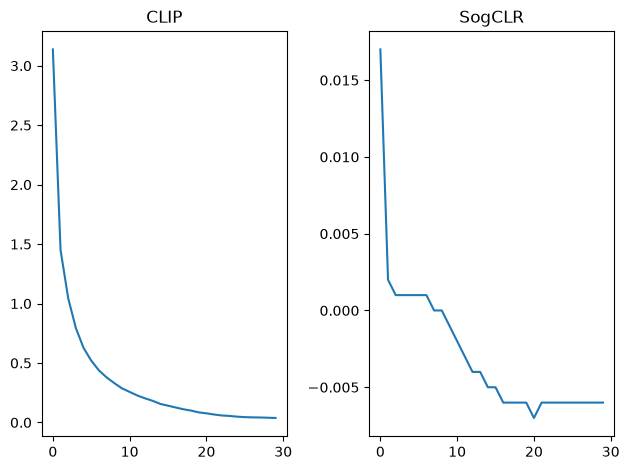

In [13]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(nrows=1, ncols=2, sharex=True)
axes = axes.flatten()
for idx, run in enumerate(['CLIP', 'SogCLR']):
    ax = axes[idx]
    df = clip_coco_df if run == 'CLIP' else sogclr_coco_df
    ax.plot(df['train_loss_ita'].astype(float))
    ax.set_title(run)
plt.tight_layout()
plt.show()

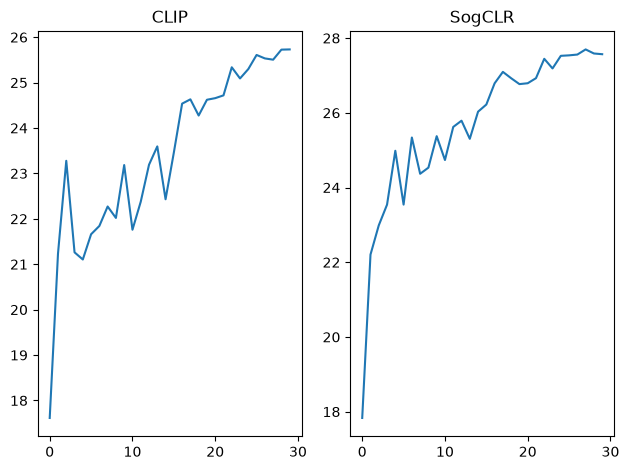

In [16]:
# print val r mean over time
import matplotlib.pyplot as plt

fig, axes = plt.subplots(nrows=1, ncols=2, sharex=True)
axes = axes.flatten()
for idx, run in enumerate(['CLIP', 'SogCLR']):
    ax = axes[idx]
    df = clip_coco_df if run == 'CLIP' else sogclr_coco_df
    ax.plot(df['val_r_mean'])
    ax.set_title(run)
plt.tight_layout()
plt.show()

In [20]:
# post image net results
clip_imagenet = load_log(f"{FINAL_EVAL['CLIP']}/zeroshot_imagenet_log.txt")
sogclr_imagenet = load_log(f"{FINAL_EVAL['SogCLR']}/zeroshot_imagenet_log.txt")

In [21]:
clip_imagenet

,zeroshot_top1,zeroshot_top3,zeroshot_top5,zeroshot_top10
0,21.148,33.854,39.894,47.858


In [22]:
sogclr_imagenet

,zeroshot_top1,zeroshot_top3,zeroshot_top5,zeroshot_top10
0,24.164,37.462,43.422,51.036
